# 阶段 2 · 任务 1：用纯 NumPy 实现两层 MLP

**目标：二维螺旋分类 + 手推反向传播 + 用训练结果验证实现。**

这份 notebook 是带讲解的参考实现。请逐节运行，尤其要自己在纸上推第 5、6 节，再对照代码；仅看到程序运行成功，还不代表已经掌握。

- 二维：每个样本只有两个坐标 `(x1, x2)`；本练习有三个类别 `0、1、2`。
- 两层：一个隐藏层和一个输出层，共两层可学习的线性变换；输入层不计入。
- 网络：`2 → 64 → 3`，隐藏层用 ReLU，输出用 Softmax，损失用平均交叉熵。
- 只需要 NumPy 和 Matplotlib；不需要 d2l、PyTorch、GPU 或下载数据。
- 本任务的数值梯度检查用于核对手写梯度；师兄要求的 **PyTorch 梯度对照（误差 < 1e-6）是下一项任务**。

**在 VS Code 中：**把文件放到项目的 `assignments/06_numpy_mlp/`，选择已有的 `dl-env` 内核，按顺序运行。下载文件中的输出是参考运行结果，重新运行后会替换成你自己的结果。建议先做到第 3 节，确认理解数据形状，再继续前向传播。

| 小节 | 要完成的工作 |
|---|---|
| 1—3 | 生成数据、分层划分训练/验证集、观察三条螺旋 |
| 4 | 参数形状、前向传播、Softmax 与交叉熵 |
| 5—7 | 手推反向传播、单样本核对、数值梯度检查 |
| 8—9 | 训练、画损失曲线和分类区域 |
| 10—11 | 保存结果、完成理解检查、集中整理重点笔记 |

验证集用于观察训练数据以外的表现，不参加梯度计算。本练习是可重复的合成数据实验，不能用它的准确率代表真实图像任务的表现。


## 1. 导入工具

使用 `float64`，便于之后比较梯度。不同随机过程分别设置随机种子，防止重跑一个绘图单元时改变训练的初始条件。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
import json

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

DATA_SEED = 2026
SPLIT_SEED = 2027
INIT_SEED = 2028
NUM_CLASSES = 3
HIDDEN_UNITS = 64

print("NumPy 版本：", np.__version__)
print("本实验使用 CPU，无需 GPU。")


NumPy 版本： 1.23.5
本实验使用 CPU，无需 GPU。


## 2. 生成二维螺旋数据

每一类生成 200 个点。用半径 `r` 和角度 `theta` 构造坐标：

$$x_1=r\cos\theta,\qquad x_2=r\sin\theta.$$

角度随半径变化，点就会弯成螺旋。三类之间相差 $2\pi/3$；角度上再加入少量随机扰动。

- `X` 的每一行是一个点，例如 `[0.12, -0.35]`。
- `y` 的每个元素是该点的类别编号。
- 半径从 0.1 开始，避免三类都在原点放置完全相同、标签却不同的样本。


In [2]:
def make_spiral(n_per_class=200, num_classes=3, noise=0.12, seed=2026):
    rng = np.random.default_rng(seed)
    X = np.empty((n_per_class * num_classes, 2), dtype=np.float64)
    y = np.empty(n_per_class * num_classes, dtype=np.int64)

    for class_id in range(num_classes):
        r = np.linspace(0.1, 1.0, n_per_class)
        theta = (
            4.0 * r
            + 2.0 * np.pi * class_id / num_classes
            + rng.normal(0.0, noise, n_per_class)
        )
        start = class_id * n_per_class
        stop = start + n_per_class
        X[start:stop, 0] = r * np.cos(theta)
        X[start:stop, 1] = r * np.sin(theta)
        y[start:stop] = class_id

    return X, y


X, y = make_spiral(seed=DATA_SEED)
print("X.shape：", X.shape)
print("y.shape：", y.shape)
print("每一类的样本数：", np.bincount(y))
print("前 5 个坐标：\n", X[:5])
print("对应标签：", y[:5])


X.shape： (600, 2)
y.shape： (600,)
每一类的样本数： [200 200 200]
前 5 个坐标：
 [[0.09539  0.030013]
 [0.094255 0.045177]
 [0.106681 0.022585]
 [0.092314 0.06615 ]
 [0.100739 0.061619]]
对应标签： [0 0 0 0 0]


## 3. 分层划分训练集和验证集，并画图

每一类各取 80% 训练、20% 验证，因此训练集有 $3\times160=480$ 个点，验证集有 $3\times40=120$ 个点。

**不能直接把当前数组的前 80% 当训练集**，因为生成时样本按类别排列。这里先在每类内部打乱索引再划分，保证两部分都包含全部类别。


训练坐标 / 标签： (480, 2) (480,)
验证坐标 / 标签： (120, 2) (120,)
训练集各类数量： [160 160 160]
验证集各类数量： [40 40 40]


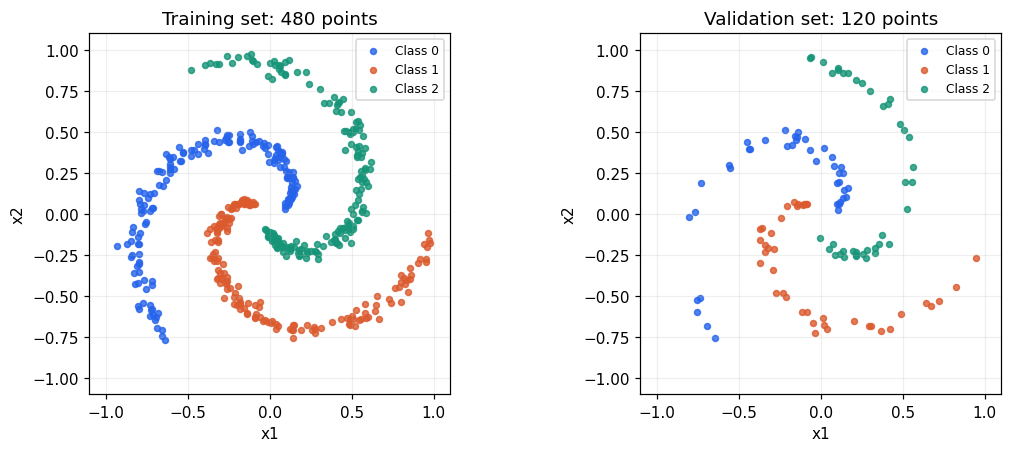

In [3]:
def stratified_split(X, y, train_fraction=0.8, seed=2027):
    rng = np.random.default_rng(seed)
    train_indices = []
    val_indices = []

    for class_id in np.unique(y):
        indices = np.flatnonzero(y == class_id)
        indices = rng.permutation(indices)
        split_at = int(len(indices) * train_fraction)
        train_indices.extend(indices[:split_at])
        val_indices.extend(indices[split_at:])

    train_indices = np.array(train_indices, dtype=np.int64)
    val_indices = np.array(val_indices, dtype=np.int64)
    rng.shuffle(train_indices)
    rng.shuffle(val_indices)

    return (X[train_indices], y[train_indices],
            X[val_indices], y[val_indices], train_indices, val_indices)


X_train, y_train, X_val, y_val, train_indices, val_indices = stratified_split(
    X, y, seed=SPLIT_SEED
)

print("训练坐标 / 标签：", X_train.shape, y_train.shape)
print("验证坐标 / 标签：", X_val.shape, y_val.shape)
print("训练集各类数量：", np.bincount(y_train))
print("验证集各类数量：", np.bincount(y_val))

assert np.intersect1d(train_indices, val_indices).size == 0
assert len(train_indices) + len(val_indices) == len(X)

CLASS_COLORS = ["#2563eb", "#db5a2e", "#159477"]
POINT_CMAP = ListedColormap(CLASS_COLORS)
REGION_CMAP = ListedColormap(["#dce8ff", "#ffe6db", "#d8f2e8"])

fig_data, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, features, labels, title in [
    (axes[0], X_train, y_train, "Training set: 480 points"),
    (axes[1], X_val, y_val, "Validation set: 120 points"),
]:
    for class_id, color in enumerate(CLASS_COLORS):
        points = features[labels == class_id]
        ax.scatter(points[:, 0], points[:, 1], s=15, color=color,
                   alpha=0.8, label=f"Class {class_id}")
    ax.set(title=title, xlabel="x1", ylabel="x2", xlim=(-1.1, 1.1), ylim=(-1.1, 1.1))
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.show()


**第一个检查点：**你应看到三种颜色的螺旋点云，而不是显微图像。每个样本是两个坐标，因此这里适合先练 MLP。此时还没有进行训练。

请确认自己能回答：`X_train[0]` 是什么？`y_train[0]` 是什么？为什么“二维数据”仍然能有三个类别？


## 4. 两层网络的前向传播

用 $N$ 表示一次参与计算的样本数，$H=64$ 表示隐藏单元数，$C=3$ 表示类别数。

$$Z_1=XW_1+b_1,\qquad A_1=\operatorname{ReLU}(Z_1),$$
$$Z_2=A_1W_2+b_2,\qquad P=\operatorname{softmax}(Z_2).$$

| 张量 | 形状 | 含义 |
|---|---|---|
| $X$ | $(N,2)$ | 输入坐标 |
| $W_1$ | $(2,64)$ | 输入到隐藏层的权重 |
| $b_1$ | $(1,64)$ | 隐藏层偏置，广播给每个样本 |
| $Z_1,A_1$ | $(N,64)$ | 隐藏层激活前/后的值 |
| $W_2$ | $(64,3)$ | 隐藏层到输出层的权重 |
| $b_2$ | $(1,3)$ | 输出层偏置 |
| $Z_2,P$ | $(N,3)$ | 三类分数 / 三类概率 |

这里每一行对应一个样本。`@` 是矩阵乘法；`*` 是逐元素乘法，两者不要混淆。

权重采用随机初始化，偏置初始化为 0。偏置初值为 0 **不代表偏置梯度为 0**，训练时仍然更新偏置。


In [4]:
def initialize_parameters(input_dim=2, hidden_units=64, num_classes=3, seed=2028):
    rng = np.random.default_rng(seed)
    return {
        "W1": rng.standard_normal((input_dim, hidden_units)) * np.sqrt(2.0 / input_dim),
        "b1": np.zeros((1, hidden_units), dtype=np.float64),
        "W2": rng.standard_normal((hidden_units, num_classes)) * np.sqrt(1.0 / hidden_units),
        "b2": np.zeros((1, num_classes), dtype=np.float64),
    }


params = initialize_parameters(hidden_units=HIDDEN_UNITS, seed=INIT_SEED)
for name, value in params.items():
    print(name, value.shape)
print("可学习参数总数：", sum(value.size for value in params.values()))


W1 (2, 64)
b1 (1, 64)
W2 (64, 3)
b2 (1, 3)
可学习参数总数： 387


Softmax 沿每一行计算：

$$P_{ic}=\frac{\exp(Z_{2,ic})}{\sum_{j=0}^{C-1}\exp(Z_{2,ij})}.$$

每行减去本行最大值不会改变 Softmax 概率，却能防止指数过大。

代码先计算稳定的对数概率 `log_probs`，再取指数得到 `probs`。平均交叉熵直接使用对数概率：

$$L=-\frac1N\sum_{i=0}^{N-1}\log P_{i,y_i}.$$

`log_probs[np.arange(N), labels]` 为每个样本取出其真实类别对应的对数概率。


In [5]:
def forward(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = np.maximum(Z1, 0.0)
    logits = A1 @ params["W2"] + params["b2"]

    shifted = logits - logits.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    probs = np.exp(log_probs)

    cache = {"X": X, "Z1": Z1, "A1": A1,
             "log_probs": log_probs, "probs": probs}
    return probs, cache


def cross_entropy_from_cache(cache, labels):
    return float(-cache["log_probs"][np.arange(len(labels)), labels].mean())


def evaluate(X, labels, params):
    probs, cache = forward(X, params)
    predictions = probs.argmax(axis=1)
    loss = cross_entropy_from_cache(cache, labels)
    accuracy = float((predictions == labels).mean())
    return loss, accuracy


probs, cache = forward(X_train, params)
print("前 5 个样本的预测概率：\n", probs[:5])
print("前 5 行概率之和：", probs[:5].sum(axis=1))
print("前 5 个预测类别：", probs[:5].argmax(axis=1))
print("前 5 个真实类别：", y_train[:5])
print("未训练时的损失、准确率：", evaluate(X_train, y_train, params))

assert probs.shape == (len(X_train), NUM_CLASSES)
assert np.allclose(probs.sum(axis=1), 1.0)


前 5 个样本的预测概率：
 [[0.624233 0.062059 0.313708]
 [0.327475 0.354659 0.317866]
 [0.574554 0.211703 0.213743]
 [0.407563 0.239267 0.35317 ]
 [0.393318 0.312197 0.294485]]
前 5 行概率之和： [1. 1. 1. 1. 1.]
前 5 个预测类别： [0 1 0 0 0]
前 5 个真实类别： [0 0 1 1 2]
未训练时的损失、准确率： (1.2464865997853067, 0.2)


## 5. 手推反向传播，再对应到代码

以下公式使用**平均交叉熵**，没有额外的正则化项。用 $T$ 表示真实标签的 one-hot 矩阵，例如类别 1 对应 `[0,1,0]`。

### 从交叉熵与 Softmax 得到输出梯度

对一个样本，$\ell=-\log p_y$，并且

$$\frac{\partial p_y}{\partial z_c}=p_y(\mathbf1[c=y]-p_c).$$

由链式法则：

$$\frac{\partial\ell}{\partial z_c}
=-\frac1{p_y}\,p_y(\mathbf1[c=y]-p_c)
=p_c-\mathbf1[c=y].$$

对 $N$ 个样本取平均后：

$$D_2\equiv\frac{\partial L}{\partial Z_2}=\frac{P-T}{N}.$$

### 输出层参数与隐藏层梯度

因为 $Z_{2,ic}=\sum_h A_{1,ih}W_{2,hc}+b_{2,c}$：

$$\frac{\partial L}{\partial W_{2,hc}}=\sum_i A_{1,ih}D_{2,ic},
\qquad \boxed{\nabla W_2=A_1^\mathsf TD_2}.$$

$$\boxed{\nabla b_2=\sum_i D_{2,i:}},\qquad
\boxed{\frac{\partial L}{\partial A_1}=D_2W_2^\mathsf T}.$$

偏置被所有样本共享，因此对样本维度求和；不能因为偏置初值为 0 就忽略它。

### 穿过 ReLU，再求第一层参数梯度

$$D_1\equiv\frac{\partial L}{\partial Z_1}
=(D_2W_2^\mathsf T)\odot\mathbf1[Z_1>0].$$

这里 $\odot$ 表示逐元素相乘。ReLU 在正数处导数为 1，在负数处为 0；在 0 处不可导，本实现约定取 0。

$$\boxed{\nabla W_1=X^\mathsf TD_1},\qquad
\boxed{\nabla b_1=\sum_iD_{1,i:}}.$$

检查形状，例如 $(64,N)@(N,3)=(64,3)$，恰好与 $W_2$ 相同。

**不要一边求梯度一边更新参数。先用同一组旧参数计算所有梯度，再统一更新。**


In [6]:
def backward(params, cache, labels):
    X = cache["X"]
    Z1 = cache["Z1"]
    A1 = cache["A1"]
    N = len(labels)

    # copy 防止修改前向传播缓存中的概率
    dZ2 = cache["probs"].copy()
    dZ2[np.arange(N), labels] -= 1.0
    dZ2 /= N

    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)

    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


grads = backward(params, cache, y_train)
for name in params:
    print(f"{name}：参数形状 {params[name].shape}，梯度形状 {grads[name].shape}")
    assert grads[name].shape == params[name].shape
print("输出层偏置初值：", params["b2"])
print("输出层偏置梯度：", grads["b2"])


W1：参数形状 (2, 64)，梯度形状 (2, 64)
b1：参数形状 (1, 64)，梯度形状 (1, 64)
W2：参数形状 (64, 3)，梯度形状 (64, 3)
b2：参数形状 (1, 3)，梯度形状 (1, 3)
输出层偏置初值： [[0. 0. 0.]]
输出层偏置梯度： [[ 0.068812 -0.062323 -0.006489]]


## 6. 用一个小网络手算一次

将隐藏单元数临时缩小为 2，输入只有一个样本 $x=[1,2]$，真实类别为 0：

$$W_1=\begin{bmatrix}1&-1\\0.5&1\end{bmatrix},\quad b_1=[0,0],
\qquad W_2=\begin{bmatrix}1&0&-1\\0&1&1\end{bmatrix},\quad b_2=[0,0,0].$$

前向传播：$Z_1=A_1=[2,1]$，$Z_2=[2,1,-1]$。

请先手算下面四步，再运行下一格核对：

1. 对 `[2,1,-1]` 求 Softmax，得到 $P$。
2. 用 $D_2=P-[1,0,0]$ 求输出层梯度。这里只有一个样本，$N=1$。
3. 用 $D_2W_2^\mathsf T$ 求隐藏层梯度；两个 ReLU 输入都大于 0。
4. 求四组参数梯度，再按 $\theta\leftarrow\theta-0.1\nabla\theta$ 更新。

这里沿用**行向量**约定：`X @ W1`，不要把权重矩阵转置错。


In [7]:
toy_X = np.array([[1.0, 2.0]])
toy_y = np.array([0])
toy_params = {
    "W1": np.array([[1.0, -1.0], [0.5, 1.0]]),
    "b1": np.zeros((1, 2)),
    "W2": np.array([[1.0, 0.0, -1.0], [0.0, 1.0, 1.0]]),
    "b2": np.zeros((1, 3)),
}

toy_probs, toy_cache = forward(toy_X, toy_params)
toy_grads = backward(toy_params, toy_cache, toy_y)
old_loss = cross_entropy_from_cache(toy_cache, toy_y)

print("隐藏层输出：", toy_cache["A1"])
print("Softmax 概率：", toy_probs)
for name, grad in toy_grads.items():
    print(f"{name} 的梯度：\n{grad}")

updated_toy = {name: value - 0.1 * toy_grads[name]
               for name, value in toy_params.items()}
new_loss, _ = evaluate(toy_X, toy_y, updated_toy)
print(f"这一步更新前损失：{old_loss:.6f}，更新后损失：{new_loss:.6f}")


隐藏层输出： [[2. 1.]]
Softmax 概率： [[0.705385 0.259496 0.035119]]
W1 的梯度：
[[-0.329735  0.294615]
 [-0.659469  0.589231]]
b1 的梯度：
[[-0.329735  0.294615]]
W2 的梯度：
[[-0.589231  0.518993  0.070238]
 [-0.294615  0.259496  0.035119]]
b2 的梯度：
[[-0.294615  0.259496  0.035119]]
这一步更新前损失：0.349012，更新后损失：0.184060


## 7. 数值梯度检查：验证手写公式

对某一个参数 $\theta_j$，用中心差分近似它的梯度：

$$g_j^{\mathrm{num}}\approx
\frac{L(\theta_j+\varepsilon)-L(\theta_j-\varepsilon)}{2\varepsilon}.$$

这相当于轻轻增大/减小一个参数，看损失怎样变化。它只用于检查，训练仍然使用高效的反向传播。

为了速度，只取前 8 个训练样本，但检查网络中的**所有参数**。ReLU 在 0 处不可导；如果微小扰动改变了正负分支，就跳过该参数的这一次比较并报告数量。计算后会恢复每个参数原值。

下面以最大绝对误差 `1e-6` 作为本次数值检查的容差。这一检查不能替代下一项任务的 PyTorch 对照。


In [8]:
def numerical_gradient_check(X_check, y_check, params, epsilon=1e-5):
    _, base_cache = forward(X_check, params)
    analytic = backward(params, base_cache, y_check)
    report = {}

    for name, parameter in params.items():
        errors = []
        skipped = 0
        for index in np.ndindex(parameter.shape):
            old_value = parameter[index]
            try:
                parameter[index] = old_value + epsilon
                _, plus_cache = forward(X_check, params)
                plus_loss = cross_entropy_from_cache(plus_cache, y_check)

                parameter[index] = old_value - epsilon
                _, minus_cache = forward(X_check, params)
                minus_loss = cross_entropy_from_cache(minus_cache, y_check)
            finally:
                parameter[index] = old_value

            same_relu_branch = np.array_equal(
                plus_cache["Z1"] > 0, minus_cache["Z1"] > 0
            )
            if not same_relu_branch:
                skipped += 1
                continue

            numerical = (plus_loss - minus_loss) / (2.0 * epsilon)
            errors.append(abs(numerical - analytic[name][index]))

        assert errors, f"{name} 没有可比较的平滑位置，请换一组检查样本。"
        report[name] = {"checked": len(errors), "skipped": skipped,
                        "max_absolute_error": float(max(errors))}
    return report


check_params = initialize_parameters(hidden_units=HIDDEN_UNITS, seed=INIT_SEED)
gradient_report = numerical_gradient_check(X_train[:8], y_train[:8], check_params)
for name, item in gradient_report.items():
    print(f"{name}: 检查 {item['checked']} 项，跳过 {item['skipped']} 项，"
          f"最大绝对误差 {item['max_absolute_error']:.3e}")
    assert item["max_absolute_error"] < 1e-6
print("数值梯度检查通过。")


W1: 检查 128 项，跳过 0 项，最大绝对误差 1.646e-11
b1: 检查 64 项，跳过 0 项，最大绝对误差 1.436e-11
W2: 检查 192 项，跳过 0 项，最大绝对误差 1.996e-11
b2: 检查 3 项，跳过 0 项，最大绝对误差 5.970e-12
数值梯度检查通过。


## 8. 训练网络

为了先看清完整训练过程，这次每次更新使用**全部 480 个训练样本**，即全批量梯度下降。每个 epoch 恰好更新一次；下一阶段再使用 DataLoader 和小批量。

固定设置：隐藏单元 64、学习率 0.5、训练 2000 个 epoch，无显式正则化。验证集只评估、不更新参数。

训练单元会重新初始化参数，因此重复运行该单元会从头开始，而不会在上次模型上继续训练。日志的 `epoch=0` 是初始模型；其他日志对应完成相应次数更新后的模型，损失与准确率使用同一时刻的参数。


In [9]:
LEARNING_RATE = 0.5
NUM_EPOCHS = 2000
LOG_EVERY = 100

params = initialize_parameters(hidden_units=HIDDEN_UNITS, seed=INIT_SEED)
initial_params = {name: value.copy() for name, value in params.items()}
history = {"epoch": [], "train_loss": [], "val_loss": [],
           "train_accuracy": [], "val_accuracy": []}


def record_metrics(epoch):
    train_loss, train_acc = evaluate(X_train, y_train, params)
    val_loss, val_acc = evaluate(X_val, y_val, params)
    values = [epoch, train_loss, val_loss, train_acc, val_acc]
    for name, value in zip(history, values):
        history[name].append(value)
    print(f"epoch {epoch:4d} | loss {train_loss:.5f} / {val_loss:.5f}"
          f" | acc {train_acc:.2%} / {val_acc:.2%}")


print("每行顺序：训练 / 验证")
record_metrics(0)
for epoch in range(1, NUM_EPOCHS + 1):
    _, cache = forward(X_train, params)
    grads = backward(params, cache, y_train)

    # 所有梯度已经算好，再统一更新全部权重和偏置
    for name in params:
        params[name] -= LEARNING_RATE * grads[name]

    if epoch % LOG_EVERY == 0 or epoch == NUM_EPOCHS:
        record_metrics(epoch)

final_train_loss, final_train_acc = evaluate(X_train, y_train, params)
final_val_loss, final_val_acc = evaluate(X_val, y_val, params)
assert np.isfinite(final_train_loss) and np.isfinite(final_val_loss)
print(f"最终训练准确率：{final_train_acc:.2%}")
print(f"最终验证准确率：{final_val_acc:.2%}")


每行顺序：训练 / 验证
epoch    0 | loss 1.24649 / 1.28176 | acc 20.00% / 15.00%
epoch  100 | loss 0.24446 / 0.29481 | acc 95.83% / 92.50%
epoch  200 | loss 0.11920 / 0.15212 | acc 99.38% / 99.17%
epoch  300 | loss 0.07575 / 0.10096 | acc 99.79% / 99.17%
epoch  400 | loss 0.05437 / 0.07491 | acc 100.00% / 100.00%
epoch  500 | loss 0.04187 / 0.05936 | acc 100.00% / 100.00%
epoch  600 | loss 0.03376 / 0.04896 | acc 100.00% / 100.00%
epoch  700 | loss 0.02808 / 0.04151 | acc 100.00% / 100.00%
epoch  800 | loss 0.02393 / 0.03592 | acc 100.00% / 100.00%
epoch  900 | loss 0.02076 / 0.03151 | acc 100.00% / 100.00%
epoch 1000 | loss 0.01825 / 0.02806 | acc 100.00% / 100.00%
epoch 1100 | loss 0.01626 / 0.02524 | acc 100.00% / 100.00%
epoch 1200 | loss 0.01464 / 0.02295 | acc 100.00% / 100.00%
epoch 1300 | loss 0.01330 / 0.02102 | acc 100.00% / 100.00%
epoch 1400 | loss 0.01216 / 0.01937 | acc 100.00% / 100.00%
epoch 1500 | loss 0.01118 / 0.01794 | acc 100.00% / 100.00%
epoch 1600 | loss 0.01034 / 0.01668

## 9. 查看训练曲线与分类区域

损失越低不等于每次准确率都立刻上升：交叉熵会继续关心概率的置信程度，而准确率只判断最大概率的类别是否正确。

决策区域的背景色表示模型对该坐标预测的类别；点的颜色是真实类别。背景色与点颜色一致，说明分类正确。远离数据点的区域没有验证样本支撑，不要据此推断模型在所有地方都可靠。


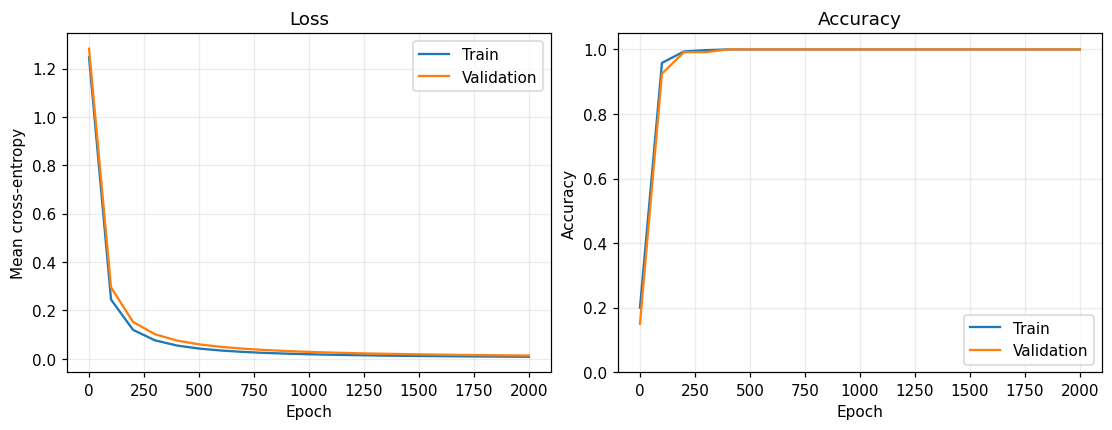

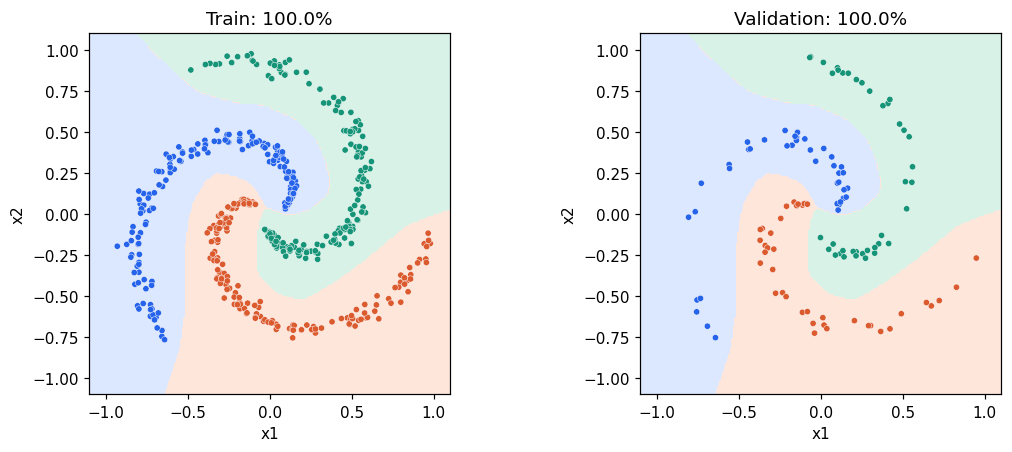

验证集混淆矩阵：行是真实类别，列是预测类别
[[40  0  0]
 [ 0 40  0]
 [ 0  0 40]]


In [10]:
fig_curves, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].plot(history["epoch"], history["train_loss"], label="Train")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Mean cross-entropy", title="Loss")
axes[1].plot(history["epoch"], history["train_accuracy"], label="Train")
axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05), title="Accuracy")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

grid_x, grid_y = np.meshgrid(np.linspace(-1.1, 1.1, 240),
                           np.linspace(-1.1, 1.1, 240))
grid_points = np.column_stack((grid_x.ravel(), grid_y.ravel()))
grid_probs, _ = forward(grid_points, params)
grid_predictions = grid_probs.argmax(axis=1).reshape(grid_x.shape)

fig_regions, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, features, labels, title in [
    (axes[0], X_train, y_train, f"Train: {final_train_acc:.1%}"),
    (axes[1], X_val, y_val, f"Validation: {final_val_acc:.1%}"),
]:
    ax.contourf(grid_x, grid_y, grid_predictions,
                levels=[-0.5, 0.5, 1.5, 2.5], cmap=REGION_CMAP)
    ax.scatter(features[:, 0], features[:, 1], c=labels, cmap=POINT_CMAP,
               vmin=0, vmax=2, s=17, edgecolors="white", linewidths=0.3)
    ax.set(title=title, xlabel="x1", ylabel="x2",
           xlim=(-1.1, 1.1), ylim=(-1.1, 1.1))
    ax.set_aspect("equal")
plt.show()

val_probs, _ = forward(X_val, params)
val_predictions = val_probs.argmax(axis=1)
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
np.add.at(confusion, (y_val, val_predictions), 1)
print("验证集混淆矩阵：行是真实类别，列是预测类别")
print(confusion)


## 10. 保存实验结果

如果内核工作目录是项目根目录，下面会优先保存到 `assignments/06_numpy_mlp/outputs`；如果工作目录就是 notebook 所在目录，则保存在其 `outputs` 下。**检查打印的实际路径**。

保存内容：三张结果图、超参数和指标、数据划分、初始/训练后参数。数据和初始参数可用于下一项 PyTorch 梯度对照，避免两套代码输入或权重不一致。

运行后，还要在 VS Code 中按 **Ctrl+S** 保存 notebook 本身；保存图像和参数不会自动保存 notebook 的单元内容。


In [11]:
working_directory = Path.cwd()
candidate = working_directory / "assignments" / "06_numpy_mlp"
assignment_directory = candidate if candidate.is_dir() else working_directory
output_directory = assignment_directory / "outputs"
output_directory.mkdir(parents=True, exist_ok=True)

fig_data.savefig(output_directory / "spiral_data.png", dpi=160, bbox_inches="tight")
fig_curves.savefig(output_directory / "training_curves.png", dpi=160, bbox_inches="tight")
fig_regions.savefig(output_directory / "decision_regions.png", dpi=160, bbox_inches="tight")

np.savez(output_directory / "spiral_dataset.npz", X_train=X_train, y_train=y_train,
         X_val=X_val, y_val=y_val, train_indices=train_indices, val_indices=val_indices)
np.savez(output_directory / "numpy_mlp_initial.npz", **initial_params)
np.savez(output_directory / "numpy_mlp_trained.npz", **params)

experiment = {
    "dataset": "synthetic three-class spiral",
    "data_seed": DATA_SEED, "split_seed": SPLIT_SEED, "init_seed": INIT_SEED,
    "input_dim": 2, "hidden_units": HIDDEN_UNITS, "num_classes": NUM_CLASSES,
    "learning_rate": LEARNING_RATE, "epochs": NUM_EPOCHS,
    "optimizer": "full-batch gradient descent", "dtype": "float64",
    "train_samples": len(y_train), "validation_samples": len(y_val),
    "train_loss": final_train_loss, "validation_loss": final_val_loss,
    "train_accuracy": final_train_acc, "validation_accuracy": final_val_acc,
    "gradient_check": gradient_report, "history": history,
    "numpy_version": np.__version__,
}
(output_directory / "metrics.json").write_text(
    json.dumps(experiment, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("结果已保存到：", output_directory.resolve())
print("接下来按 Ctrl+S 保存 notebook。")


结果已保存到： [参考运行目录]/06_numpy_mlp/outputs
接下来按 Ctrl+S 保存 notebook。


## 11. 完成标准与一次重点笔记

完成这份作业需要同时有**运行结果**和**自己的解释**：

- [ ] 能说明为什么输入维度是 2、输出维度是 3，而网络称为“两层”。
- [ ] 能写出四组参数及梯度的形状。
- [ ] 能从 Softmax 和交叉熵推导 $D_2=(P-T)/N$。
- [ ] 能独立完成第 6 节手算，并解释为什么两个偏置也要更新。
- [ ] 数值梯度检查通过，能说明中心差分在检查什么。
- [ ] 损失下降，训练/验证点云能被正确分类，已保存训练曲线和分类区域。
- [ ] 用自己的话记录一次实验总结，然后保存 notebook。

**笔记只集中整理这次的重点。**完成后在 Obsidian 的 `01-learning-notes` 下新建 `两层MLP与反向传播`，写下：

1. 一张前向计算图：$X\rightarrow Z_1\rightarrow A_1\rightarrow Z_2\rightarrow P\rightarrow L$。
2. 上面四组参数的梯度公式，并附第 6 节自己的手算过程。
3. 为什么 `axis=0` 用于偏置梯度、为什么除以样本数 $N$、为什么先求完梯度再更新。
4. 自己运行得到的超参数、损失/准确率和一张分类区域图；说明这是合成数据结果。

不需要把所有代码复制到笔记。等下一项 PyTorch 对照和后续训练任务完成后，再集中整理“训练循环模板”。

**下一项任务：**用 PyTorch 写同样的 MLP，加载相同输入与权重，用 `loss.backward()` 与这里的手写梯度逐项比较。NumPy 的 `X @ W` 与 PyTorch `Linear` 的权重存储方向不同，下一项会专门处理转置。

参考资料（用于补充阅读）：

- [Stanford CS231n：螺旋数据与两层网络案例](https://cs231n.github.io/neural-networks-case-study/)
- [NumPy：随机数生成器](https://numpy.org/doc/stable/reference/random/)

本 notebook 使用独立的三臂螺旋生成方式、固定分层划分、稳定对数 Softmax 与全参数中心差分检查；参考资料的运行数字不会与本实验相同。
